## Identifying the ML approach, relevant algorithms to the dataset and the expected output of your application

The application will be using a **CNN** for **classifying** images of crops to identify the specific crop diseases or pest present and provide a remedy. The dataset has images of the crop disease and the appropriate label, thus **supervised learning** will work best for this scenario. The model will be returning the **name of the crop disease or pest** and a **confidence score** which will be used on a mapping that will return the remedy.

## The data cleaning process beginning from exploration to the final dataset for modelling

The datasets used were the [Crop Diseases Classification](https://www.kaggle.com/datasets/mexwell/crop-diseases-classification) dataset, [PlantVillage](https://www.kaggle.com/datasets/abdallahalidev/plantvillage-dataset) dataset, and the [20k+ Multi-Class Crop Disease Images](https://www.kaggle.com/datasets/jawadali1045/20k-multi-class-crop-disease-images) dataset obtained from the Kaggle Website.

### Import Model Weights

Get the model weights from the original training run to use with the other datasets.

In [ ]:
import os
import shutil
from google.colab import drive

# Mount Google Drive
drive.mount('/content/drive')

# Path directly to Colab Notebooks
DRIVE_INPUT_WEIGHTS = '/content/drive/MyDrive/Colab Notebooks/dataset1_best_crop_model.pth'
LOCAL_WEIGHTS_PATH = './dataset1_best_crop_model.pth'

# Copy weights to local fast storage
if os.path.exists(DRIVE_INPUT_WEIGHTS):
    shutil.copy(DRIVE_INPUT_WEIGHTS, LOCAL_WEIGHTS_PATH)
    print(f"✓ Successfully copied weights to fast local storage: '{LOCAL_WEIGHTS_PATH}'")
else:
    print(f"✗ Checkpoint not found at '{DRIVE_INPUT_WEIGHTS}'. Proceeding with fresh training.")

Mounted at /content/drive
✓ Successfully copied weights to fast local storage: './dataset1_best_crop_model.pth'


### Installation of the datasets

In [2]:
import os
from google.colab import userdata

os.environ['KAGGLE_USERNAME'] = userdata.get('KAGGLE_USERNAME')
os.environ['KAGGLE_KEY'] = userdata.get('KAGGLE_API_KEY')

# Download and extract the first dataset
!kaggle datasets download -d jawadali1045/20k-multi-class-crop-disease-images
!unzip -q 20k-multi-class-crop-disease-images.zip -d ./multi_dataset

# Download and extract the second dataset
!kaggle datasets download -d abdallahalidev/plantvillage-dataset
!unzip -q plantvillage-dataset.zip -d ./village_dataset

# Download and extract the original trained dataset to avoid critical forgetfulness
!kaggle datasets download -d mexwell/crop-diseases-classification
!unzip -q crop-diseases-classification.zip -d ./cassava_dataset

Dataset URL: https://www.kaggle.com/datasets/jawadali1045/20k-multi-class-crop-disease-images
License(s): CC0-1.0
100% 2.34G/2.34G [01:00<00:00, 41.8MB/s]

Dataset URL: https://www.kaggle.com/datasets/abdallahalidev/plantvillage-dataset
License(s): CC-BY-NC-SA-4.0
100% 2.04G/2.04G [00:52<00:00, 42.1MB/s]

Dataset URL: https://www.kaggle.com/datasets/mexwell/crop-diseases-classification
License(s): other
100% 2.00G/2.00G [00:54<00:00, 39.7MB/s]



### Data Cleaning

#### Changing the format of the Crop-Diseases-Classification dataset from an indexed list mapping to a test train folder split to match the format of the PlantVillage Dataset and the 20k+ Multi-Class Crop Disease Images.

In [ ]:
import json
import os
import shutil
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path
import pandas as pd

CASSAVA_RAW_DIR = Path('./cassava_dataset')
CASSAVA_FORMATTED_DIR = Path('./cassava_formatted')

# Mapping for numerical or abbreviated labels to unified class names
CASSAVA_LABEL_MAP = {
    '0': 'Cassava Bacterial Blight',
    '1': 'Cassava Brown Streak Disease',
    '2': 'Cassava Green Mottle',
    '3': 'Cassava Mosaic Disease',
    '4': 'Healthy Cassava',
    'cbb': 'Cassava Bacterial Blight',
    'cbsd': 'Cassava Brown Streak Disease',
    'cgm': 'Cassava Green Mottle',
    'cmd': 'Cassava Mosaic Disease',
    'healthy': 'Healthy Cassava',
}

VALID_EXTS = {'.png', '.jpg', '.jpeg', '.bmp', '.webp'}


def _copy_file(src_dest_tuple):
  """Helper worker function to perform file copy."""
  src, dest = src_dest_tuple
  shutil.copy(str(src), str(dest))


def format_cassava_dataset():
  if not CASSAVA_RAW_DIR.exists():
    print(f"✗ Raw directory '{CASSAVA_RAW_DIR}' not found.")
    return

  CASSAVA_FORMATTED_DIR.mkdir(parents=True, exist_ok=True)
  copy_tasks = []

  # Dataset uses a CSV mapping 
  csv_files = list(CASSAVA_RAW_DIR.rglob('*.csv'))

  if csv_files:
    df = pd.read_csv(csv_files[0])
    img_col = next(
        col
        for col in df.columns
        if 'image' in col.lower() or 'file' in col.lower()
    )
    label_col = next(
        col
        for col in df.columns
        if 'label' in col.lower() or 'target' in col.lower()
    )

    # Pre create all unique destination directories once
    unique_labels = {
        CASSAVA_LABEL_MAP.get(str(lbl), str(lbl)) for lbl in df[label_col]
    }
    for label in unique_labels:
      (CASSAVA_FORMATTED_DIR / label).mkdir(parents=True, exist_ok=True)

    # Build a 1 pass file index lookup: filename -> absolute Path
    print("Indexing dataset files...")
    file_index = {
        p.name: p
        for p in CASSAVA_RAW_DIR.rglob('*')
        if p.is_file() and p.suffix.lower() in VALID_EXTS
    }

    # Prepare copy jobs using instant hash map lookup 
    for _, row in df.iterrows():
      img_name = str(row[img_col])
      raw_label = str(row[label_col])
      clean_label = CASSAVA_LABEL_MAP.get(raw_label, raw_label)

      if img_name in file_index:
        src = file_index[img_name]
        dest = CASSAVA_FORMATTED_DIR / clean_label / src.name
        copy_tasks.append((src, dest))

  # Dataset uses class subfolders
  else:
    for img_path in CASSAVA_RAW_DIR.rglob('*'):
      if img_path.is_file() and img_path.suffix.lower() in VALID_EXTS:
        raw_folder = img_path.parent.name
        clean_label = CASSAVA_LABEL_MAP.get(raw_folder, raw_folder)

        dest_dir = CASSAVA_FORMATTED_DIR / clean_label
        dest_dir.mkdir(parents=True, exist_ok=True)
        copy_tasks.append((img_path, dest_dir / img_path.name))

  # Execute file copying concurrently using worker threads
  print(f"Copying {len(copy_tasks)} images...")
  with ThreadPoolExecutor(max_workers=os.cpu_count() * 2) as executor:
    list(executor.map(_copy_file, copy_tasks))

  print(
      f"✓ Successfully formatted {len(copy_tasks)} cassava images into"
      f" '{CASSAVA_FORMATTED_DIR}'"
  )


format_cassava_dataset()

Indexing dataset files...
Copying 17938 images...
✓ Successfully formatted 17938 cassava images into 'cassava_formatted'


#### Install ONNX

In [4]:
!pip install onnx onnxscript -q

#### Clean the dataset by correcting naming schemes, removing corrup or blurred images, dropping duplicates and managing the split distribution

In [ ]:
from concurrent.futures import ThreadPoolExecutor
import hashlib
import os
from pathlib import Path
import shutil
import cv2
import numpy as np
import pandas as pd
from PIL import Image
from sklearn.model_selection import train_test_split

# Unified class mapper
UNIFIED_CLASS_MAP = {
    # PlantVillage Maize
    "Corn_(maize)___Common_rust_": "Common Rust Maize",
    "Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot": "Gray Leaf Spot Maize",
    "Corn_(maize)___Northern_Leaf_Blight": "Northern Leaf Blight Maize",
    "Corn_(maize)___healthy": "Healthy Maize",
    # 20k Dataset Maize
    "Gray_Leaf_Spot": "Gray Leaf Spot Maize",
    "Gray Leaf Spot": "Gray Leaf Spot Maize",
    "Common_Rust": "Common Rust Maize",
    "Common Rust": "Common Rust Maize",
    "Healthy Maize": "Healthy Maize",
    "maize ear rot": "Maize Ear Rot",
    "maize fall armyworm": "Army Worm",
    "maize stem borer": "Maize Stem Borer",
    # PlantVillage Tomato
    "Tomato___Bacterial_spot": "Bacterial Spot Tomato",
    "Tomato___Early_blight": "Early Blight Tomato",
    "Tomato___Late_blight": "Late Blight Tomato",
    "Tomato___Leaf_Mold": "Leaf Mold Tomato",
    "Tomato___Septoria_leaf_spot": "Septoria Leaf Spot Tomato",
    "Tomato___Spider_mites Two-spotted_spider_mite": "Spider Mites Tomato",
    "Tomato___Target_Spot": "Target Spot Tomato",
    "Tomato___Tomato_Yellow_Leaf_Curl_Virus": "Yellow Leaf Curl Virus Tomato",
    "Tomato___Tomato_mosaic_virus": "Mosaic Virus Tomato",
    "Tomato___healthy": "Healthy Tomato",
    # PlantVillage Potato
    "Potato___Early_blight": "Early Blight Potato",
    "Potato___Late_blight": "Late Blight Potato",
    "Potato___healthy": "Healthy Potato",
    # PlantVillage Bell Pepper
    "Pepper,_bell___Bacterial_spot": "Bacterial Spot Pepper",
    "Pepper,_bell___healthy": "Healthy Pepper",
    # PlantVillage Other Crops
    "Apple___Apple_scab": "Apple Scab",
    "Apple___Black_rot": "Black Rot Apple",
    "Apple___Cedar_apple_rust": "Cedar Apple Rust",
    "Apple___healthy": "Healthy Apple",
    "Cherry_(including_sour)___Powdery_mildew": "Powdery Mildew Cherry",
    "Cherry_(including_sour)___healthy": "Healthy Cherry",
    "Grape___Black_rot": "Black Rot Grape",
    "Grape___Esca_(Black_Measles)": "Black Measles Grape",
    "Grape___Leaf_blight_(Isariopsis_Leaf_Spot)": "Leaf Blight Grape",
    "Grape___healthy": "Healthy Grape",
    "Peach___Bacterial_spot": "Bacterial Spot Peach",
    "Peach___healthy": "Healthy Peach",
    "Strawberry___Leaf_scorch": "Leaf Scorch Strawberry",
    "Strawberry___healthy": "Healthy Strawberry",
    # 20k Dataset Specific Fixes
    "Wheat___Healthy": "Healthy Wheat",
    "Wheat Healthy": "Healthy Wheat",
    "Wheat___Yellow_Rust": "Wheat Yellow Rust",
    "Sugarcane Healthy": "Healthy Sugarcane",
    "Wheat Brown leaf Rust": "Wheat Brown Leaf Rust",
    "Wheat Brown leaf rust": "Wheat Brown Leaf Rust",
    "Bacterial Blight in cotton": "Bacterial Blight In Cotton",
    "bacterial_blight in Cotton": "Bacterial Blight In Cotton",
    "Becterial Blight in Rice": "Bacterial Blight In Rice",
    "thirps on  cotton": "Thrips",
    "thirps on   cotton": "Thrips",
    "RedRot sugarcane": "Red Rot Sugarcane",
    "RedRust sugarcane": "Red Rust Sugarcane",
    "American Bollworm on Cotton": "Bollworm",
    "Anthracnose on Cotton": "Anthracnose On Cotton",
    "Army worm": "Army Worm",
    "Brownspot": "Brown Spot",
    "Cotton Aphid": "Aphid",
    "Flag Smut": "Flag Smut",
    "Healthy cotton": "Healthy Cotton",
    "Leaf Curl": "Leaf Curl",
    "Leaf smut": "Leaf Smut",
    "Mosaic sugarcane": "Mosaic Sugarcane",
    "Rice Blast": "Rice Blast",
    "Tungro": "Tungro",
    "Wheat Stem fly": "Wheat Stem Fly",
    "Wheat aphid": "Wheat Aphid",
    "Wheat black rust": "Wheat Black Rust",
    "Wheat leaf blight": "Wheat Leaf Blight",
    "Wheat mite": "Wheat Mite",
    "Wheat powdery mildew": "Wheat Powdery Mildew",
    "Wheat scab": "Wheat Scab",
    "Wilt": "Wilt",
    "Yellow Rust Sugarcane": "Yellow Rust Sugarcane",
    "bollrot on Cotton": "Boll Rot On Cotton",
    "bollworm on Cotton": "Bollworm",
    "cotton mealy bug": "Mealy Bug",
    "cotton whitefly": "Whitefly",
    "pink bollworm in cotton": "Pink Bollworm",
    "red cotton bug": "Red Cotton Bug",
    # Cassava Dataset
    "Cassava Bacterial Blight": "Cassava Bacterial Blight",
    "Cassava Brown Streak Disease": "Cassava Brown Streak Disease",
    "Cassava Green Mottle": "Cassava Green Mottle",
    "Cassava Mosaic Disease": "Cassava Mosaic Disease",
    "Healthy Cassava": "Healthy Cassava",
}

# Image Inspector
def fast_inspect_image(img_path, blur_threshold=100.0):
  """Verifies file integrity, computes MD5 hash, and checks for blur on a thumbnail."""
  # Fast integrity check
  try:
    with Image.open(img_path) as img:
      img.verify()
  except Exception:
    return None, "corrupted"

  # Fast binary hashing
  try:
    hasher = hashlib.md5()
    with open(img_path, "rb") as f:
      for chunk in iter(lambda: f.read(131072), b""):
        hasher.update(chunk)
    file_hash = hasher.hexdigest()
  except Exception:
    return None, "corrupted"

  # Fast OpenCV blur check 
  try:
    img_gray = cv2.imread(str(img_path), cv2.IMREAD_GRAYSCALE)
    if img_gray is None:
      return None, "corrupted"

    # Resize to 256x256 thumbnail to make Laplacian calculation near instant
    thumb = cv2.resize(img_gray, (256, 256), interpolation=cv2.INTER_NEAREST)
    variance = cv2.Laplacian(thumb, cv2.CV_64F).var()
    if variance < blur_threshold:
      return None, "blurry"
  except Exception:
    return None, "corrupted"

  # Label Normalization
  raw_folder_name = img_path.parent.name
  if raw_folder_name in UNIFIED_CLASS_MAP:
    clean_label = UNIFIED_CLASS_MAP[raw_folder_name]
  elif "_" in raw_folder_name:
    clean_label = " ".join(raw_folder_name.replace("_", " ").split())
  else:
    clean_label = raw_folder_name

  return {
      "file_path": img_path,
      "label": clean_label,
      "hash": file_hash,
  }, "valid"


# Parallel pipeline
def process_and_combine_datasets_fast(
    input_dirs=["./multi_dataset", "./village_dataset", "./cassava_formatted"],
    output_dir="./final_dataset",
    blur_threshold=100.0,
    test_size=0.2,
    num_workers=8,
):
  valid_exts = (".png", ".jpg", ".jpeg", ".bmp", ".webp")
  image_paths = []

  print("Step 1: Gathering all file paths...")
  for root_path in input_dirs:
    root_dir = Path(root_path)
    if root_dir.exists():
      for p in root_dir.rglob("*"):
        if p.is_file() and p.suffix.lower() in valid_exts:
          image_paths.append(p)

  print(
      f"Found {len(image_paths)} total images. Inspecting in parallel using"
      f" {num_workers} threads..."
  )

  valid_records = []
  seen_hashes = set()

  corrupted_count = 0
  blurry_count = 0
  duplicate_count = 0

  # Multi-threaded execution across CPU cores
  with ThreadPoolExecutor(max_workers=num_workers) as executor:
    futures = [
        executor.submit(fast_inspect_image, path, blur_threshold)
        for path in image_paths
    ]

    for future in futures:
      result, status = future.result()
      if status == "corrupted":
        corrupted_count += 1
      elif status == "blurry":
        blurry_count += 1
      elif status == "valid":
        # Sequential deduplication in memory
        if result["hash"] in seen_hashes:
          duplicate_count += 1
        else:
          seen_hashes.add(result["hash"])
          valid_records.append(result)

  print("\nFiltering Summary:")
  print(f" - Retained Valid Images: {len(valid_records)}")
  print(f" - Corrupted Images Dropped: {corrupted_count}")
  print(f" - Duplicate Images Dropped: {duplicate_count}")
  print(f" - Blurry Images Dropped: {blurry_count}")

  if not valid_records:
    print("No valid images found!")
    return

  df = pd.DataFrame(valid_records)

  # Filter sparse classes (<2 images)
  class_counts = df["label"].value_counts()
  sparse_classes = class_counts[class_counts < 2].index
  if len(sparse_classes) > 0:
    df = df[~df["label"].isin(sparse_classes)]

  print("\nStep 2: Performing Stratified 80/20 Train/Validation Split...")
  train_df, val_df = train_test_split(
      df, test_size=test_size, stratify=df["label"], random_state=42
  )

  print("\nStep 3: Copying files to output directory in parallel...")
  output_path = Path(output_dir)
  if output_path.exists():
    shutil.rmtree(output_path)

  # Pre-create all class directories safely before spawning threads
  for split_name in ["train", "validation"]:
    for label in df["label"].unique():
      (output_path / split_name / label).mkdir(parents=True, exist_ok=True)

  def copy_file_worker(row_and_split):
    row, split_name = row_and_split
    dest_dir = output_path / split_name / row["label"]

    # Prefix with short MD5 hash so merged classes with identical filenames never overwrite or race
    dest_file = dest_dir / f"{row['hash'][:8]}_{row['file_path'].name}"
    shutil.copy(str(row["file_path"]), str(dest_file))

  copy_tasks = [(row, "train") for _, row in train_df.iterrows()] + [
      (row, "validation") for _, row in val_df.iterrows()
  ]

  with ThreadPoolExecutor(max_workers=num_workers) as executor:
    list(executor.map(copy_file_worker, copy_tasks))

  print(
      f"\nPipeline Finished! Speed-optimized dataset created at: '{output_dir}'"
  )


# Run optimized pipeline using 8 thread workers
process_and_combine_datasets_fast(num_workers=8)

Step 1: Gathering all file paths...
Found 199471 total images. Inspecting in parallel using 8 threads...


/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:950: UserWarning: Corrupt EXIF data.  Expecting to read 4 bytes but only got 0. 
  warnings.warn(str(msg))



Filtering Summary:
 - Retained Valid Images: 184020
 - Corrupted Images Dropped: 0
 - Duplicate Images Dropped: 5697
 - Blurry Images Dropped: 9754

Step 2: Performing Stratified 80/20 Train/Validation Split...

Step 3: Copying files to output directory in parallel...

Pipeline Finished! Speed-optimized dataset created at: './final_dataset'


####  Drop Extreme Minority classes

In [6]:
import os
import shutil
from pathlib import Path
from collections import defaultdict

def drop_extreme_minority_classes(dataset_path='./final_dataset', min_total_threshold=20):
    """
    Scans dataset split folders and permanently removes class subfolders
    whose combined total (train + validation) images fall below min_total_threshold.
    """
    base_dir = Path(dataset_path)
    if not base_dir.exists():
        print(f"Error: Directory '{dataset_path}' does not exist.")
        return

    valid_exts = ('.png', '.jpg', '.jpeg', '.bmp', '.webp')
    class_counts = defaultdict(int)
    class_folder_paths = defaultdict(list)

    # 1. Count images across all splits for every class
    for split in base_dir.iterdir():
        if split.is_dir():
            for class_dir in split.iterdir():
                if class_dir.is_dir():
                    class_name = class_dir.name
                    img_count = sum(1 for f in class_dir.glob('*') if f.is_file() and f.suffix.lower() in valid_exts)

                    class_counts[class_name] += img_count
                    class_folder_paths[class_name].append(class_dir)

    # 2. Identify minority classes below the threshold
    to_drop = {cls: count for cls, count in class_counts.items() if count < min_total_threshold}

    if not to_drop:
        print(f"No classes found with fewer than {min_total_threshold} total images.")
        return

    print(f"Found {len(to_drop)} extreme minority classes (< {min_total_threshold} total images):")
    for cls, count in sorted(to_drop.items(), key=lambda x: x[1]):
        print(f" - '{cls}': {count} total images")

    # 3. Delete minority class directories
    dropped_folders_count = 0
    dropped_images_count = 0

    for cls in to_drop.keys():
        for folder_path in class_folder_paths[cls]:
            if folder_path.exists():
                img_count = sum(1 for f in folder_path.glob('*') if f.is_file() and f.suffix.lower() in valid_exts)
                shutil.rmtree(folder_path)
                dropped_folders_count += 1
                dropped_images_count += img_count

    print(f"\nCleanup finished!")
    print(f" - Successfully removed {len(to_drop)} minority classes ({dropped_folders_count} subfolders).")
    print(f" - Total dropped images: {dropped_images_count}")

# Execute cleanup for classes with fewer than 20 total images
drop_extreme_minority_classes('./final_dataset', min_total_threshold=20)

Found 1 extreme minority classes (< 20 total images):
 - 'Boll Rot On Cotton': 3 total images

Cleanup finished!
 - Successfully removed 1 minority classes (2 subfolders).
 - Total dropped images: 3


#### Drop Non-Kenyan Crops

In [7]:
import shutil
from pathlib import Path

def filter_dataset_classes(dataset_path='./final_dataset', classes_to_keep=None):
    """
    Scans dataset split folders ('train' and 'validation') and permanently deletes
    any class subfolders that are NOT in the `classes_to_keep` set.
    """
    if not classes_to_keep:
        print("Error: Please provide a set or list of classes_to_keep.")
        return

    base_dir = Path(dataset_path)
    if not base_dir.exists():
        print(f"Error: Directory '{dataset_path}' does not exist.")
        return

    keep_set = set(classes_to_keep)
    valid_exts = ('.png', '.jpg', '.jpeg', '.bmp', '.webp')

    dropped_classes = set()
    dropped_folders_count = 0
    dropped_images_count = 0

    # Scan 'train' and 'validation' split directories
    for split in base_dir.iterdir():
        if split.is_dir():
            for class_dir in split.iterdir():
                if class_dir.is_dir() and class_dir.name not in keep_set:
                    img_count = sum(
                        1 for f in class_dir.glob('*')
                        if f.is_file() and f.suffix.lower() in valid_exts
                    )
                    shutil.rmtree(class_dir)
                    dropped_classes.add(class_dir.name)
                    dropped_folders_count += 1
                    dropped_images_count += img_count

    if not dropped_classes:
        print("No unselected class folders were found to drop.")
        return

    print(f"Cleanup finished! Dropped {len(dropped_classes)} unselected classes ({dropped_folders_count} subfolders):")
    for cls in sorted(dropped_classes):
        print(f" - '{cls}'")
    print(f"\nTotal dropped images: {dropped_images_count}")



# SELECT CLASSES TO KEEP
CLASSES_TO_KEEP = {
    # Maize
    "Common Rust Maize",
    "Gray Leaf Spot Maize",
    "Healthy Maize",
    "Maize Ear Rot",
    "Maize Stem Borer",
    "Northern Leaf Blight Maize",

    # Cassava
    "Cassava Bacterial Blight",
    "Cassava Brown Streak Disease",
    "Cassava Green Mottle",
    "Cassava Mosaic Disease",
    "Healthy Cassava",

    # Tomato
    "Bacterial Spot Tomato",
    "Early Blight Tomato",
    "Healthy Tomato",
    "Late Blight Tomato",
    "Leaf Mold Tomato",
    "Mosaic Virus Tomato",
    "Septoria Leaf Spot Tomato",
    "Spider Mites Tomato",
    "Target Spot Tomato",
    "Yellow Leaf Curl Virus Tomato",

    # Potato
    "Early Blight Potato",
    "Healthy Potato",
    "Late Blight Potato",

    # Bell Pepper
    "Bacterial Spot Pepper",
    "Healthy Pepper",

    # Sugarcane
    "Healthy Sugarcane",
    "Mosaic Sugarcane",
    "Red Rot Sugarcane",
    "Red Rust Sugarcane",
    "Yellow Rust Sugarcane",

    # Wheat
    "Healthy Wheat",
    "Wheat Aphid",
    "Wheat Black Rust",
    "Wheat Brown Leaf Rust",
    "Wheat Leaf Blight",
    "Wheat Mite",
    "Wheat Powdery Mildew",
    "Wheat Scab",
    "Wheat Stem Fly",
    "Wheat Yellow Rust",

    # Rice
    "Bacterial Blight In Rice",
    "Brown Spot",
    "Leaf Smut",
    "Rice Blast",
    "Tungro",

    # General Pests & Diseases
    "Aphid",
    "Army Worm",
    "Bollworm",
    "Leaf Curl",
    "Mealy Bug",
    "Orange Haunglongbing (Citrus greening)",
    "Pink Bollworm",
    "Thrips",
    "Whitefly",
    "Wilt",
}

# Execute cleanup
filter_dataset_classes('./final_dataset', classes_to_keep=CLASSES_TO_KEEP)

Cleanup finished! Dropped 23 unselected classes (46 subfolders):
 - 'Anthracnose On Cotton'
 - 'Apple Scab'
 - 'Bacterial Blight In Cotton'
 - 'Bacterial Spot Peach'
 - 'Black Measles Grape'
 - 'Black Rot Apple'
 - 'Black Rot Grape'
 - 'Blueberry healthy'
 - 'Cedar Apple Rust'
 - 'Flag Smut'
 - 'Healthy Apple'
 - 'Healthy Cherry'
 - 'Healthy Cotton'
 - 'Healthy Grape'
 - 'Healthy Peach'
 - 'Healthy Strawberry'
 - 'Leaf Blight Grape'
 - 'Leaf Scorch Strawberry'
 - 'Powdery Mildew Cherry'
 - 'Raspberry healthy'
 - 'Red Cotton Bug'
 - 'Soybean healthy'
 - 'Squash Powdery mildew'

Total dropped images: 67573


### Exploratory Data Analysis

#### Check Distribution After Dataset Cleanup

In [8]:
import os
import pandas as pd

def print_final_dataset_summary(dataset_path='./final_dataset'):
    records = []
    valid_exts = ('.png', '.jpg', '.jpeg', '.bmp', '.webp')

    train_dir = os.path.join(dataset_path, 'train')
    val_dir = os.path.join(dataset_path, 'validation')

    def count_classes(split_path):
        counts = {}
        if not os.path.exists(split_path):
            return counts
        for root, _, files in os.walk(split_path):
            if root != split_path:
                class_name = os.path.basename(root)
                img_count = sum(1 for f in files if f.lower().endswith(valid_exts))
                counts[class_name] = counts.get(class_name, 0) + img_count
        return counts

    train_counts = count_classes(train_dir)
    val_counts = count_classes(val_dir)
    all_classes = sorted(list(set(train_counts.keys()).union(set(val_counts.keys()))))

    class_names_list = []
    train_counts_list = []
    val_counts_list = []
    total_counts_list = []

    for cls in all_classes:
        tr = train_counts.get(cls, 0)
        va = val_counts.get(cls, 0)

        class_names_list.append(cls)
        train_counts_list.append(tr)
        val_counts_list.append(va)
        total_counts_list.append(tr + va)

        records.append({
            'Plant Name': cls,
            'Train Image Count': tr,
            'Validation Image Count': va
        })

    df = pd.DataFrame(records)
    if not df.empty:
        total_row = pd.DataFrame([{
            'Plant Name': 'TOTAL',
            'Train Image Count': df['Train Image Count'].sum(),
            'Validation Image Count': df['Validation Image Count'].sum()
        }])
        df = pd.concat([df, total_row], ignore_index=True)

    print(df.to_string(index=False))

    return class_names_list, train_counts_list, val_counts_list, total_counts_list

# Run check on newly created dataset and capture lists for plotting
class_names, train_counts, val_counts, total_counts = print_final_dataset_summary()

                            Plant Name  Train Image Count  Validation Image Count
                                 Aphid                212                      53
                             Army Worm                345                      86
              Bacterial Blight In Rice                950                     237
                 Bacterial Spot Pepper               2393                     598
                 Bacterial Spot Tomato               5098                    1275
                              Bollworm                 51                      13
                            Brown Spot                629                     157
              Cassava Bacterial Blight                737                     184
          Cassava Brown Streak Disease               1462                     365
                  Cassava Green Mottle               1594                     398
                Cassava Mosaic Disease               8820                    2205
                

#### Plot Distribution of Classes

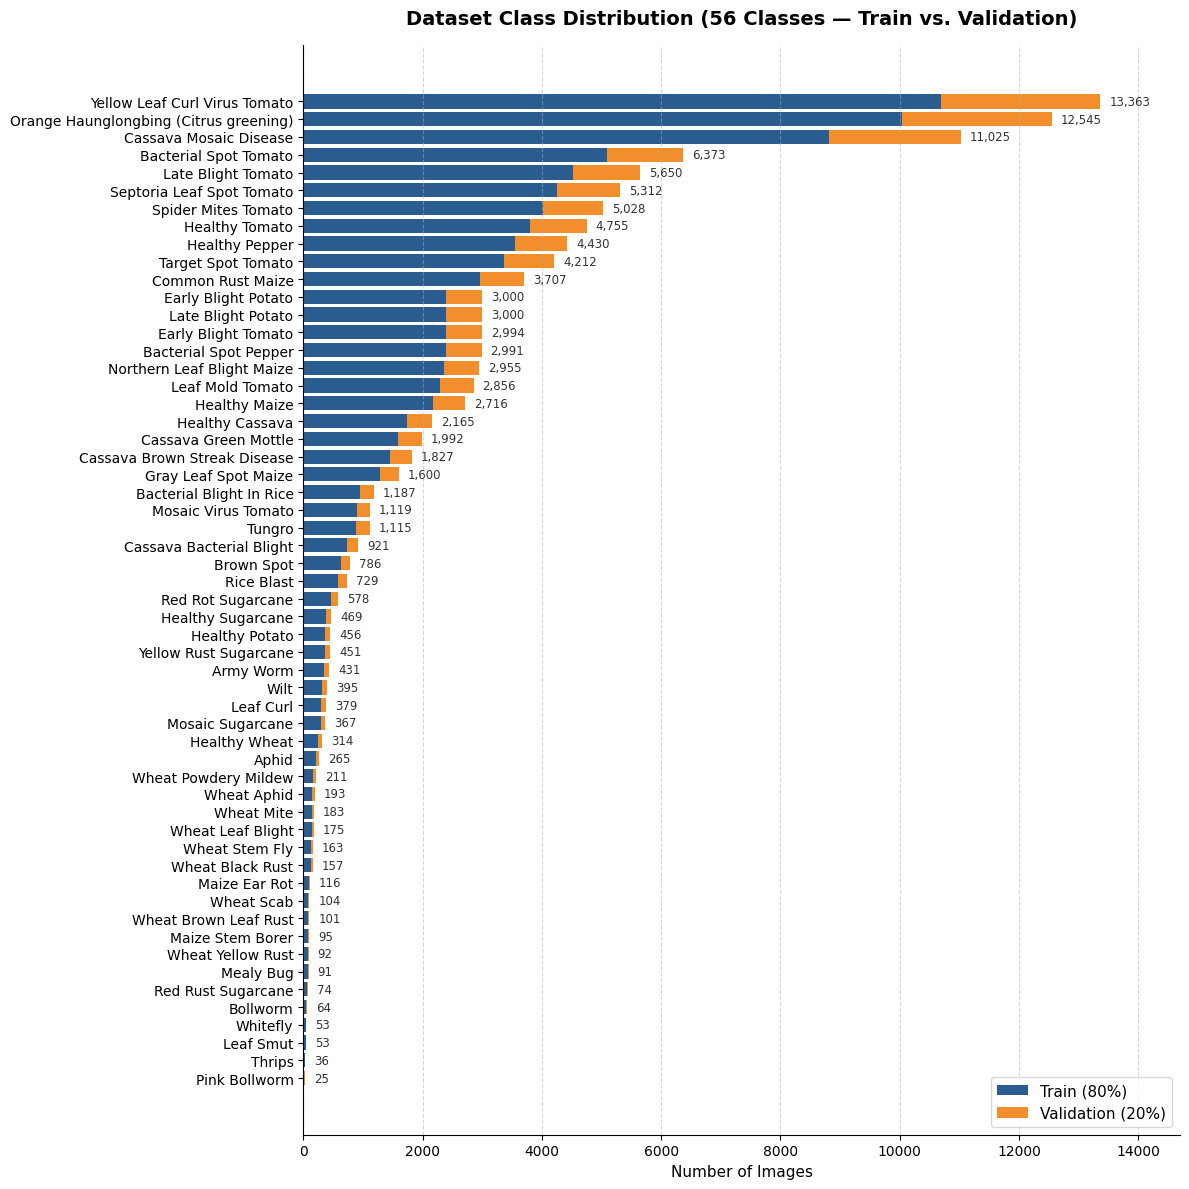

In [9]:
import pandas as pd
import matplotlib.pyplot as plt

plot_df = pd.DataFrame({
    "Plant Name": class_names,
    "Train Image Count": train_counts,
    "Validation Image Count": val_counts,
    "Total": total_counts
}).sort_values("Total", ascending=True)

fig, ax = plt.subplots(figsize=(12, 12))
ax.barh(plot_df["Plant Name"], plot_df["Train Image Count"], label="Train (80%)", color="#2b5c8f")
ax.barh(plot_df["Plant Name"], plot_df["Validation Image Count"], left=plot_df["Train Image Count"], label="Validation (20%)", color="#f28e2b")

for index, (_, row) in enumerate(plot_df.iterrows()):
    ax.text(row["Total"] + 150, index, f"{row['Total']:,}", va="center", fontsize=8.5, color="#333333")

ax.set_title(f"Dataset Class Distribution ({len(class_names)} Classes — Train vs. Validation)", fontsize=14, fontweight="bold", pad=15)
ax.set_xlabel("Number of Images", fontsize=11)
ax.set_xlim(0, plot_df["Total"].max() * 1.1)
ax.grid(axis="x", linestyle="--", alpha=0.5)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.legend(loc="lower right", frameon=True, fontsize=11)

plt.tight_layout()
plt.savefig("class_distribution.png", dpi=300)
plt.show()

#### Data Discovery Results

- The dataset is unevenly distributed with Yellow Leaf Curl Virus Tomato having approximately 11% of the data.
- Pesta like the Pink Bollworm are highly under represented making up less than 1% of the data.
- The images all use the standard RGB colour format.
- The images are not of the same standard dimensions and thus the images will need to be trimmed into a uniform square before training of the CNN begins.

## Modelling approach taken on the CNN model

The CNN model will be using **Depthwise Separable (DS) Convolutions**  and **Squeeze and Excitation (SE) Attention Modules** to capture the features in the **SEDS Convolution Block**. SEDS was chosen over the standard concolution method since it improves performace. It will also compress the features through global pooling to reduce the chances of overfitting and use the AdamW optimizer to tune the models weights.  

### Validation
The dataset will be split with 80% used for training and 20% used for validating the model with a manual seed of 42 for reproducibility. It also uses a weighted random sampler to ensure that the model performs well across the other under-represented classes.

### Training and Evaluation while loading the weights of the previous model

In [ ]:
import os
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, WeightedRandomSampler
from torchvision import transforms, datasets
from sklearn.metrics import classification_report
from PIL import Image

# Acceleration Configuration
torch.set_float32_matmul_precision('high')
torch.backends.cudnn.benchmark = True

train_losses, test_losses = [], []
train_correct, test_correct = [], []

# Architecture Definitions
class SEDSConvBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super(SEDSConvBlock, self).__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_channels, in_channels, kernel_size=3, padding=1, groups=in_channels, bias=False),
            nn.BatchNorm2d(in_channels),
            nn.SiLU(),
            nn.Conv2d(in_channels, out_channels, kernel_size=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.SiLU()
        )
        self.se = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Conv2d(out_channels, max(1, out_channels // 4), kernel_size=1),
            nn.SiLU(),
            nn.Conv2d(max(1, out_channels // 4), out_channels, kernel_size=1),
            nn.Sigmoid()
        )

    def forward(self, x):
        x = self.conv(x)
        weight = self.se(x)
        return x * weight

class FullyOptimizedCropCNN(nn.Module):
    def __init__(self, num_classes):
        super(FullyOptimizedCropCNN, self).__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(32),
            nn.SiLU(),
            nn.MaxPool2d(2, 2),

            SEDSConvBlock(32, 64),
            nn.MaxPool2d(2, 2),

            SEDSConvBlock(64, 128),
            nn.MaxPool2d(2, 2),

            SEDSConvBlock(128, 256),
            nn.MaxPool2d(2, 2),

            SEDSConvBlock(256, 256),
            nn.AdaptiveAvgPool2d((1, 1))
        )
        self.classifier = nn.Sequential(
            nn.Dropout(0.4),
            nn.Linear(256, 128),
            nn.SiLU(),
            nn.Dropout(0.2),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = torch.flatten(x, 1)
        x = self.classifier(x)
        return x

# HIGH-SPEED DATA PIPELINE & PREFETCH DATALOADERS
img_size = 224
batch_size = 128

# Streamlined transform pipeline to eliminate CPU resize & augmentation bottlenecks
train_transform = transforms.Compose([
    transforms.Resize((img_size, img_size), interpolation=transforms.InterpolationMode.BILINEAR),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

val_transform = transforms.Compose([
    transforms.Resize((img_size, img_size), interpolation=transforms.InterpolationMode.BILINEAR),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

train_dataset = datasets.ImageFolder('./final_dataset/train', transform=train_transform)
val_dataset = datasets.ImageFolder('./final_dataset/validation', transform=val_transform)

class_names = train_dataset.classes
num_classes = len(class_names)
print(f"Loaded {len(train_dataset)} training images and {len(val_dataset)} validation images across {num_classes} classes.")

# Calculate Smooth Weighted Random Sampler
train_targets = [label for _, label in train_dataset.samples]
class_counts = torch.bincount(torch.tensor(train_targets))
class_weights_sampler = 1.0 / (class_counts.float() ** 0.5)
sample_weights = [class_weights_sampler[t] for t in train_targets]

sampler = WeightedRandomSampler(
    weights=sample_weights,
    num_samples=len(sample_weights),
    replacement=True
)

# High-throughput DataLoaders with prefetch_factor=2
train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    sampler=sampler,
    num_workers=2,
    pin_memory=True,
    persistent_workers=True,
    prefetch_factor=2
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2,
    pin_memory=True,
    persistent_workers=True,
    prefetch_factor=2
)

# INITIALIZATION & CHECKPOINT WEIGHT LOADING
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = FullyOptimizedCropCNN(num_classes).to(device, memory_format=torch.channels_last)

CHECKPOINT_PATH = './dataset1_best_crop_model.pth'

if os.path.exists(CHECKPOINT_PATH):
    print(f"Loading pretrained backbone from '{CHECKPOINT_PATH}'...")
    checkpoint = torch.load(CHECKPOINT_PATH, map_location=device)
    raw_state_dict = checkpoint.get('state_dict', checkpoint) if isinstance(checkpoint, dict) else checkpoint

    clean_state_dict = {
        k.replace('_orig_mod.', '').replace('module.', ''): v
        for k, v in raw_state_dict.items()
    }

    model_dict = model.state_dict()
    transfer_dict = {}
    skipped_layers = []

    for k, v in clean_state_dict.items():
        if k in model_dict:
            if v.shape == model_dict[k].shape:
                transfer_dict[k] = v
            else:
                skipped_layers.append(f"{k} (Shape mismatch: {v.shape} vs {model_dict[k].shape})")
        else:
            skipped_layers.append(f"{k} (Layer not in model)")

    model_dict.update(transfer_dict)
    model.load_state_dict(model_dict)

    print(f"✓ Successfully loaded {len(transfer_dict)} backbone layers into custom architecture!")
    if skipped_layers:
        print("ℹ Re-initialized mismatched output layers for new dataset:")
        for skip in skipped_layers:
            print(f"   - {skip}")
else:
    print(f"✗ Checkpoint '{CHECKPOINT_PATH}' not found. Initializing clean model.")

# Bypass torch.compile to avoid T4 graph autotune overhead
compiled_model = model
print("✓ Direct GPU model execution initialized (bypassing torch.compile overhead)\n")

# OPTIMIZER, LOSS, AND SCHEDULER SETUP
criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
optimizer = optim.AdamW(compiled_model.parameters(), lr=1e-3, weight_decay=1e-3)

epochs = 10  # Set to 20 epochs for fast high-accuracy target
scheduler = optim.lr_scheduler.OneCycleLR(
    optimizer,
    max_lr=3.5e-3,
    steps_per_epoch=len(train_loader),
    epochs=epochs,
    pct_start=0.3
)

scaler = torch.amp.GradScaler('cuda')

# FAST TRAINING & VALIDATION LOOP

best_val_acc = 0.0
train_size = len(train_dataset)
val_size = len(val_dataset)

print(f"Starting optimized training on {device} for {epochs} epochs at 224x224 resolution...\n")

for epoch in range(epochs):
    # Training Phase
    compiled_model.train()
    running_train_loss = 0.0
    train_correct_count = 0

    for inputs, labels in train_loader:
        inputs = inputs.to(device, memory_format=torch.channels_last, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.amp.autocast('cuda'):
            outputs = compiled_model(inputs)
            loss = criterion(outputs, labels)

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(compiled_model.parameters(), max_norm=1.0)

        scaler.step(optimizer)
        scaler.update()
        scheduler.step()

        running_train_loss += loss.item() * inputs.size(0)
        train_correct_count += (outputs.argmax(1) == labels).sum().item()

    epoch_train_loss = running_train_loss / train_size
    train_acc = train_correct_count / train_size

    # Validation Phase
    compiled_model.eval()
    running_val_loss = 0.0
    val_correct_count = 0

    with torch.no_grad():
        for inputs, labels in val_loader:
            inputs = inputs.to(device, memory_format=torch.channels_last, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            with torch.amp.autocast('cuda'):
                outputs = compiled_model(inputs)
                loss = criterion(outputs, labels)

            running_val_loss += loss.item() * inputs.size(0)
            val_correct_count += (outputs.argmax(1) == labels).sum().item()

    epoch_val_loss = running_val_loss / val_size
    val_acc = val_correct_count / val_size

    train_losses.append(epoch_train_loss)
    test_losses.append(epoch_val_loss)
    train_correct.append(train_acc)
    test_correct.append(val_acc)

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model.state_dict(), "best_crop_model.pth")
        saved_flag = " (Model Saved)"
    else:
        saved_flag = ""

    print(f"Epoch {epoch+1:02d}/{epochs} | "
          f"Train Loss: {epoch_train_loss:.4f} | "
          f"Val Loss: {epoch_val_loss:.4f} | "
          f"Train Acc: {train_acc:.4f} | "
          f"Val Acc: {val_acc:.4f}{saved_flag}")

print(f"\nTraining Complete! Best Validation Accuracy: {best_val_acc:.4f}\n")

# PER-CLASS EVALUATION REPORT
print("--- PER-CLASS PERFORMANCE ANALYSIS ---")
model.load_state_dict(torch.load("best_crop_model.pth"))
model.eval()

all_preds, all_labels = [], []
with torch.no_grad():
    for inputs, labels in val_loader:
        inputs = inputs.to(device, memory_format=torch.channels_last)
        with torch.amp.autocast('cuda'):
            outputs = model(inputs)
        all_preds.extend(outputs.argmax(1).cpu().numpy())
        all_labels.extend(labels.numpy())

print(classification_report(all_labels, all_preds, target_names=class_names))

Loaded 93156 training images and 23288 validation images across 56 classes.
Loading pretrained backbone from './dataset1_best_crop_model.pth'...
✓ Successfully loaded 72 backbone layers into custom architecture!
ℹ Re-initialized mismatched output layers for new dataset:
   - classifier.4.weight (Shape mismatch: torch.Size([5, 128]) vs torch.Size([56, 128]))
   - classifier.4.bias (Shape mismatch: torch.Size([5]) vs torch.Size([56]))
✓ Direct GPU model execution initialized (bypassing torch.compile overhead)

Starting optimized training on cuda for 10 epochs at 224x224 resolution...



/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:950: UserWarning: Corrupt EXIF data.  Expecting to read 4 bytes but only got 0. 
  warnings.warn(str(msg))


Epoch 01/10 | Train Loss: 2.7947 | Val Loss: 1.5822 | Train Acc: 0.3223 | Val Acc: 0.7083 (Model Saved)
Epoch 02/10 | Train Loss: 1.6213 | Val Loss: 1.1897 | Train Acc: 0.6979 | Val Acc: 0.8383 (Model Saved)
Epoch 03/10 | Train Loss: 1.3180 | Val Loss: 1.0576 | Train Acc: 0.8063 | Val Acc: 0.8823 (Model Saved)
Epoch 04/10 | Train Loss: 1.1728 | Val Loss: 1.0290 | Train Acc: 0.8579 | Val Acc: 0.8915 (Model Saved)
Epoch 05/10 | Train Loss: 1.0875 | Val Loss: 0.9466 | Train Acc: 0.8871 | Val Acc: 0.9189 (Model Saved)
Epoch 06/10 | Train Loss: 1.0248 | Val Loss: 0.9250 | Train Acc: 0.9085 | Val Acc: 0.9247 (Model Saved)
Epoch 07/10 | Train Loss: 0.9741 | Val Loss: 0.8934 | Train Acc: 0.9268 | Val Acc: 0.9359 (Model Saved)
Epoch 08/10 | Train Loss: 0.9425 | Val Loss: 0.8749 | Train Acc: 0.9374 | Val Acc: 0.9432 (Model Saved)
Epoch 09/10 | Train Loss: 0.9189 | Val Loss: 0.8684 | Train Acc: 0.9453 | Val Acc: 0.9470 (Model Saved)
Epoch 10/10 | Train Loss: 0.9082 | Val Loss: 0.8683 | Train Acc:

### Manual Accuracy Test

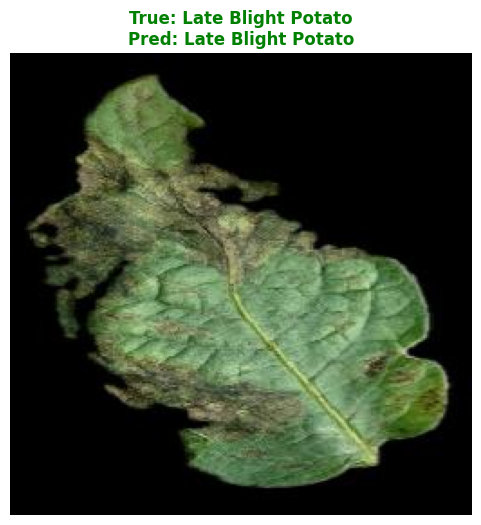

In [11]:
import random
import torch
import matplotlib.pyplot as plt
%matplotlib inline
from PIL import Image

# Pick a random index from the validation dataset
idx = random.randint(0, len(val_dataset) - 1)

# Get the transformed image tensor and true label index
img_tensor, true_idx = val_dataset[idx]

# Get the original image file path directly from ImageFolder
img_path, _ = val_dataset.samples[idx]

# Get Model Prediction
model.eval()
with torch.no_grad():
    # Pass tensor with channels_last layout and FP16 autocast matching training configuration
    input_batch = img_tensor.unsqueeze(0).to(device, memory_format=torch.channels_last)
    with torch.amp.autocast('cuda'):
        outputs = model(input_batch)
    pred_idx = outputs.argmax(1).item()

# Retrieve Human-Readable Class Names
true_name = class_names[true_idx]
pred_name = class_names[pred_idx]

# Display the Image and Prediction Result
display_img = Image.open(img_path)
plt.figure(figsize=(6, 6))
plt.imshow(display_img)

is_correct = (true_idx == pred_idx)
title_color = 'green' if is_correct else 'red'

plt.title(f"True: {true_name}\nPred: {pred_name}", color=title_color, fontsize=12, fontweight='bold')
plt.axis('off')
plt.show()

### Plot The results

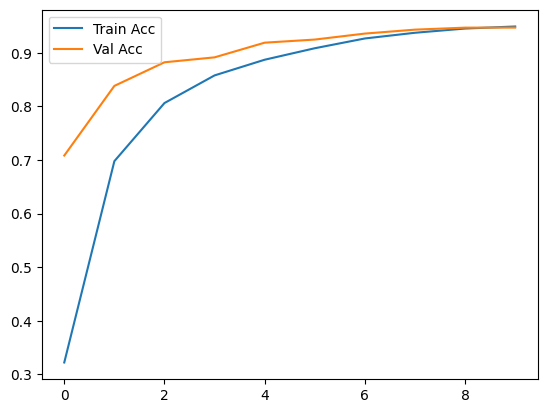

In [12]:
# Plot Training vs Validation Accuracy
plt.plot(train_correct, label='Train Acc')
plt.plot(test_correct, label='Val Acc')
plt.legend()
plt.show()

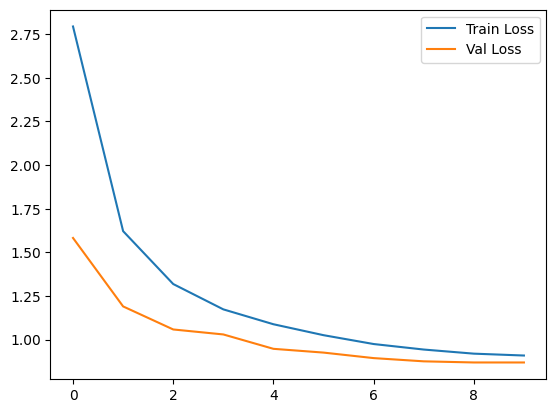

In [13]:
# Plot Training vs Validation Loss
plt.plot(train_losses, label='Train Loss')
plt.plot(test_losses, label='Val Loss')
plt.legend()
plt.show()

### Export the model with ONNX

In [14]:
import os
import torch
import onnx
from google.colab import files

print("Preparing model for standalone ONNX export...")

# Unwrap torch.compile wrapper if active
raw_model = model._orig_mod if hasattr(model, '_orig_mod') else model

# Move model to CPU & reset memory layout from channels_last back to contiguous
raw_model = raw_model.to(device='cpu', memory_format=torch.contiguous_format)
raw_model.eval()

# Dummy Input on CPU (224x224 RGB Image)
dummy_input = torch.randn(1, 3, 224, 224, dtype=torch.float32)

onnx_filename = "crop_disease_model.onnx"
labels_filename = "labels.txt"

# Export Model with Full Embedded Weights (opset 17 for maximum layer compatibility)
torch.onnx.export(
    raw_model,
    dummy_input,
    onnx_filename,
    export_params=True,             # Store trained weight tensors directly inside the file
    opset_version=17,               # Stable modern ONNX runtime opset
    do_constant_folding=True,       # Pre-calculate constant nodes for inference speed
    input_names=['input'],          # Single input node name for mobile/edge runtimes
    output_names=['output'],        # Single output node name (75 class logits)
    dynamic_axes={
        'input': {0: 'batch_size'},
        'output': {0: 'batch_size'}
    },
    dynamo=False
)

# Verify Structural Integrity & Ensure Single Fully-Integrated ONNX Binary
onnx_model = onnx.load(onnx_filename)
onnx.checker.check_model(onnx_model)

# Save as a single self-contained binary file (guarantees no separate external weight files)
onnx.save(onnx_model, onnx_filename, save_as_external_data=False)
print(f"✓ ONNX model exported & verified as a fully self-contained binary: '{onnx_filename}'")

# Save Class Names File
with open(labels_filename, 'w') as f:
    for cls in class_names:
        f.write(f"{cls}\n")

print(f"\n✓ Saved {len(class_names)} class labels to '{labels_filename}'")

# Auto-download export artifacts in Google Colab
print("\nInitiating download of model artifacts...")
files.download(onnx_filename)
files.download(labels_filename)

Preparing model for standalone ONNX export...


/tmp/ipykernel_1953/3602804007.py:22: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(


✓ ONNX model exported & verified as a fully self-contained binary: 'crop_disease_model.onnx'

✓ Saved 56 class labels to 'labels.txt'

Initiating download of model artifacts...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Other methods used to validate the results of the base model

Numerous methods were explored along the way, such as:
| Architecture / Method | Configuration / Parameters | Best Result (Accuracy) |
| :--- | :--- | :---: |
| **Standard CNN**    | $128 \times 128$ block sizes, Low epochs (20) | 0.45 |
| **Standard CNN**    | $224 \times 224$ block sizes, Low epochs (20) | 0.68 |
| **Standard CNN**    | $128 \times 128$ block sizes, High learning rates, low epochs (10–20) | 0.64 |
| **Standard CNN**    | $128 \times 128$ block sizes, Low learning rates, high epochs (30+) | 0.84 |
| **SEDS Architecture**    | $128 \times 128$ block sizes, Moderate epochs (25) | 0.77 |
| **SEDS Architecture**    | $224 \times 224$ block sizes, High epochs (30+) | **0.91** |
| **Knowledge Distillation**    | $224 \times 224$ block sizes, EfficientNet-B0 as post-trained teacher for smaller CNN | 0.87 |
| **SEDS Architecture**    | 3 Datasets (All 75 Classes), $224 \times 224$ block sizes, Low epochs (10) | **0.96** |
| **SEDS Architecture (Current File)**    | 3 Datasets (Removed Non Kenyan Crops (56 Classes)), $224 \times 224$ block sizes, Low epochs (10) | **0.95** |

The model's validation scores proved that each architecture yeilds vastly different results. Based on the tests done, the validation scores proved to be consistent to their capabilities.  
